# PROG8431 — Solutions to Highway Congestion
## Workshop C+D: Data Transformation and Linear Regression

**Group members:** Jasper Lim (9117038), John Buni (9115726), Eche Oji (9078881)  
**GitHub repository:** https://github.com/JohnBuni/Data-Analysis-Project-Group4.git

**Purpose.** Transform and augment the 2024 Ontario provincial highway segment data with the 1988–2024 traffic-volume dataset. Predict 2024 Annual Average Daily Traffic (AADT), compare simple linear regression models, and select an interpretable final multiple linear regression model.

**Secondary data source:** https://www.library.mto.gov.on.ca/SydneyPLUS/TechPubs/Portal/tp/tvSplash.aspx

## 1. Data setup and exploration

This notebook combines the 2024 Ontario provincial highway
traffic dataset with historical traffic measurements from
1988–2024.

We first examine both datasets to understand their structure,
data types, missing values and potential variables for
predicting 2024 AADT.

The required libraries are pandas, NumPy, matplotlib,
seaborn, SciPy, statsmodels, scikit-learn and openpyxl.
Both datasets are stored in the `data` folder.

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from scipy.stats import spearmanr, ks_2samp, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load the original and historical datasets
df = pd.read_excel(
    "./data/Provincial Highways Traffic Volumes 2024 AADT Only.xlsx"
)

historical = pd.read_csv(
    "./data/Traffic_Volumes_1988-2024.csv",
    encoding="cp1252",
    dtype=str
)

# Examine dataset dimensions and sample records
print("Original dataset shape:", df.shape)
display(df.head())

print("Historical dataset shape:", historical.shape)
display(historical.head())

Original dataset shape: (2712, 5)


,Highway,Location Description From,Location Description To,Distance (KM),2024 AADT
0,QEW,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,CENTRAL AV IC,0.230,13400.0
1,QEW,CENTRAL AV IC,CONCESSION RD IC-1,0.933,19100.0
2,QEW,CONCESSION RD IC-1,THOMPSON RD IC-2,1.045,18300.0
3,QEW,THOMPSON RD IC-2,GILMORE RD IC-5,2.450,22600.0
4,QEW,GILMORE RD IC-5,BOWEN RD IC-7,2.059,26300.0


Historical dataset shape: (62548, 25)


,LHRS,Offset,Year,Hwy No,Hwy No Suffix,Hwy. Type,Description,Station #,Region,Length,...,Design Hr. Dir Split %,Design Hr. Dir Split Higher Volume Direction,AADT,SADT,SAWDT,WADT,Truck %,Truck AADTT,Alpha Code,Count Code
0,10000,0.000,1988,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"19,800","25,700","24,200","16,600",21.8,"4,300",B,9
1,10000,0.000,1989,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"20,200","25,700","24,400","17,400",20.6,"4,150",B,9
2,10000,0.000,1990,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"22,100","27,600","26,100","19,200",18.3,"4,050",B,9
3,10000,0.000,1991,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"22,100","27,800","27,600","19,200",19.2,"4,250",B,9
4,10000,0.000,1992,1,NaN,FWY,FORT ERIE-GODERICH ST-PEACE BRIDGE PLAZA,5,CENTRAL,0.230,...,70,NaN,"22,200","27,300","26,400","19,300",21.4,"4,750",B,9


In [2]:
# Examine the original dataset
print("Original dataset structure:")
df.info()

print("\nOriginal dataset missing values (%):")
display((df.isnull().mean() * 100).round(2))

print("\nOriginal dataset descriptive statistics:")
display(df.describe().round(2))

# Examine missing values in the historical dataset
print("\nHistorical dataset structure:")
historical.info()

print("\nHistorical dataset missing values (%):")
display((historical.isnull().mean() * 100).round(2))

Original dataset structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2712 entries, 0 to 2711
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Highway                    2408 non-null   object 
 1   Location Description From  2408 non-null   object 
 2   Location Description To    2408 non-null   object 
 3   Distance (KM)              2101 non-null   float64
 4   2024 AADT                  1810 non-null   float64
dtypes: float64(2), object(3)
memory usage: 106.1+ KB

Original dataset missing values (%):


Highway                      11.21
Location Description From    11.21
Location Description To      11.21
Distance (KM)                22.53
2024 AADT                    33.26
dtype: float64


Original dataset descriptive statistics:


,Distance (KM),2024 AADT
count,2101.00,1810.00
mean,9.12,31808.32
std,13.86,66712.33
min,0.10,10.00
25%,2.07,2012.50
50%,4.74,7350.00
75%,10.20,23500.00
max,178.60,511400.00



Historical dataset structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62548 entries, 0 to 62547
Data columns (total 25 columns):
 #   Column                                        Non-Null Count  Dtype 
---  ------                                        --------------  ----- 
 0   LHRS                                          62548 non-null  object
 1   Offset                                        62548 non-null  object
 2   Year                                          62548 non-null  object
 3   Hwy No                                        62548 non-null  object
 4   Hwy No Suffix                                 1632 non-null   object
 5   Hwy. Type                                     62548 non-null  object
 6   Description                                   62548 non-null  object
 7   Station #                                     62015 non-null  object
 8   Region                                        62548 non-null  object
 9   Length                                   

LHRS                                             0.00
Offset                                           0.00
Year                                             0.00
Hwy No                                           0.00
Hwy No Suffix                                   97.39
Hwy. Type                                        0.00
Description                                      0.00
Station #                                        0.85
Region                                           0.00
Length                                           0.85
Conn. Link Length                               99.64
Secondary Description                           99.07
PDCS #                                           0.82
Pattern Type                                     0.82
DHV %                                            2.29
Design Hr. Dir Split %                           2.40
Design Hr. Dir Split Higher Volume Direction    73.76
AADT                                             2.29
SADT                        

## 2. Data cleaning and augmentation

The historical traffic dataset provides additional highway
characteristics and traffic measurements from 1988–2024.

We clean both datasets and create matching identifiers using
highway numbers and normalized location descriptions.

Only historical traffic measurements through 2023 will be used
as predictors, preventing 2024 traffic information from
influencing predictions of 2024 AADT.

In [3]:
# Remove original records with missing essential values
df_clean = df.dropna(subset=[
    "Highway",
    "Location Description From",
    "Distance (KM)",
    "2024 AADT"
]).copy()

# Retain positive distance and traffic measurements
df_clean = df_clean[
    (df_clean["Distance (KM)"] > 0) &
    (df_clean["2024 AADT"] > 0)
].copy()

# Create a working copy of the historical dataset
historical_clean = historical.copy()

# Convert numerical columns from text to numeric values
numeric_columns = [
    "Year", "Length", "AADT", "SADT", "SAWDT", "WADT",
    "Truck %", "Truck AADTT", "DHV %",
    "Design Hr. Dir Split %"
]

for column in numeric_columns:
    historical_clean[column] = pd.to_numeric(
        historical_clean[column].str.replace(",", "", regex=False),
        errors="coerce"
    )

# Separate historical predictor data from 2024 records
historical_prior = historical_clean[
    historical_clean["Year"] < 2024
].copy()

print("Original rows before cleaning:", len(df))
print("Original rows after cleaning:", len(df_clean))
print("Historical rows before 2024:", len(historical_prior))

display(historical_prior[numeric_columns].describe().round(2))

Original rows before cleaning: 2712
Original rows after cleaning: 1810
Historical rows before 2024: 60165


,Year,Length,AADT,SADT,SAWDT,WADT,Truck %,Truck AADTT,DHV %,Design Hr. Dir Split %
count,60165.00,60150.00,59308.00,59308.00,59308.00,59308.00,59301.00,59308.00,59308.00,59237.00
mean,2005.68,9.32,25454.31,28677.82,28888.12,22769.68,14.02,3150.19,11.51,46.81
std,10.22,12.68,54595.25,58786.97,60542.46,50311.52,9.67,6025.86,3.29,24.56
min,1988.00,0.10,10.00,20.00,20.00,10.00,0.00,0.00,0.00,0.00
25%,1997.00,2.25,1950.00,2550.00,2450.00,1550.00,8.00,210.00,10.00,51.00
50%,2006.00,5.21,6450.00,7900.00,7600.00,5400.00,11.00,720.00,10.00,55.00
75%,2014.00,10.78,18800.00,22600.00,22100.00,16125.00,17.00,2200.00,12.00,60.00
max,2023.00,150.30,501200.00,548300.00,547000.00,452300.00,164.40,49600.00,28.00,101.00


### Matching highway segments

The two datasets use different highway identifiers and location
formats. We standardize these values to identify corresponding
highway segments before merging the datasets.

We examine matching coverage and duplicate identifiers to reduce
the risk of incorrectly combining unrelated highway segments.

In [4]:
# Standardize highway identifiers
def normalize_highway(values):
    return (
        values.astype("string")
        .str.strip()
        .str.upper()
        .str.replace(r"\.0$", "", regex=True)
        .replace({"QEW": "1"})
    )

# Standardize location descriptions
def normalize_location(values):
    return (
        values.astype("string")
        .str.upper()
        .str.replace(r"[^A-Z0-9]+", " ", regex=True)
        .str.strip()
    )

# Create matching identifiers in the original dataset
df_clean["Highway_Key"] = normalize_highway(df_clean["Highway"])

df_clean["Location_Key"] = normalize_location(
    df_clean["Location Description From"]
)

df_clean["Merge_Key"] = (
    df_clean["Highway_Key"] + "|" + df_clean["Location_Key"]
)

# Create matching identifiers in the historical dataset
historical_clean["Highway_Key"] = normalize_highway(
    historical_clean["Hwy No"]
) + historical_clean["Hwy No Suffix"].fillna("").str.strip().str.upper()

historical_clean["Location_Key"] = normalize_location(
    historical_clean["Description"]
)

historical_clean["Merge_Key"] = (
    historical_clean["Highway_Key"] + "|" +
    historical_clean["Location_Key"]
)

# Separate records for matching and historical predictors
historical_2024 = historical_clean[
    historical_clean["Year"] == 2024
].copy()

historical_prior = historical_clean[
    historical_clean["Year"] < 2024
].copy()

# Check matching coverage
matched = df_clean["Merge_Key"].isin(historical_2024["Merge_Key"])
matched_prior = df_clean["Merge_Key"].isin(historical_prior["Merge_Key"])

print("Cleaned highway segments:", len(df_clean))
print("Segments matching 2024 records:", matched.sum())
print("2024 match percentage:", round(matched.mean() * 100, 2))
print("Segments matching historical records:", matched_prior.sum())

# Identify potentially ambiguous identifiers
print("\nDuplicate original identifiers:",
      df_clean["Merge_Key"].duplicated().sum())

print("Duplicate 2024 identifiers:",
      historical_2024["Merge_Key"].duplicated().sum())

print("Duplicate historical segment-year identifiers:",
      historical_prior.duplicated(["Merge_Key", "Year"]).sum())

Cleaned highway segments: 1810
Segments matching 2024 records: 1809
2024 match percentage: 99.94
Segments matching historical records: 1809

Duplicate original identifiers: 0
Duplicate 2024 identifiers: 0
Duplicate historical segment-year identifiers: 0


### Historical feature construction

The historical dataset provides multiple years of traffic
measurements for each highway segment. We summarize these
records into one row per segment.

We construct variables representing historical traffic volumes,
traffic growth, variability, seasonal traffic, truck traffic,
and highway characteristics.

Only measurements recorded before 2024 are used as predictors.
This prevents data leakage when predicting 2024 AADT.

In [5]:
# Replace invalid percentage measurements with missing values
percentage_columns = [
    "Truck %",
    "DHV %",
    "Design Hr. Dir Split %"
]

for column in percentage_columns:
    invalid = (
        (historical_prior[column] < 0) |
        (historical_prior[column] > 100)
    )
    historical_prior.loc[invalid, column] = np.nan

# Select historical years to represent long-term traffic changes
selected_years = [
    1988, 1995, 2000, 2005, 2010, 2015,
    2019, 2020, 2021, 2022, 2023
]

# Convert annual traffic measurements into separate columns
annual_aadt = historical_prior.pivot(
    index="Merge_Key",
    columns="Year",
    values="AADT"
)

annual_aadt = annual_aadt.reindex(columns=selected_years)
annual_aadt.columns = [
    f"AADT_{year}" for year in selected_years
]

# Calculate historical summary statistics for each segment
historical_summary = historical_prior.groupby("Merge_Key").agg(
    Historical_AADT_mean=("AADT", "mean"),
    Historical_AADT_median=("AADT", "median"),
    Historical_AADT_min=("AADT", "min"),
    Historical_AADT_max=("AADT", "max"),
    Historical_AADT_std=("AADT", "std"),
    Historical_observation_count=("AADT", "count"),
    Mean_SADT=("SADT", "mean"),
    Mean_SAWDT=("SAWDT", "mean"),
    Mean_WADT=("WADT", "mean"),
    Mean_Truck_pct=("Truck %", "mean"),
    Mean_Truck_AADTT=("Truck AADTT", "mean"),
    Mean_DHV_pct=("DHV %", "mean"),
    Mean_Directional_Split=("Design Hr. Dir Split %", "mean")
)

# Calculate relative historical traffic variability
historical_summary["Historical_AADT_cv"] = (
    historical_summary["Historical_AADT_std"] /
    historical_summary["Historical_AADT_mean"].replace(0, np.nan)
)

# Calculate traffic growth between 2019 and 2023
annual_aadt["AADT_Growth_2019_2023"] = (
    (annual_aadt["AADT_2023"] - annual_aadt["AADT_2019"]) /
    annual_aadt["AADT_2019"].replace(0, np.nan)
) * 100

# Obtain highway characteristics from the latest historical record
characteristics = (
    historical_prior.sort_values("Year")
    .drop_duplicates("Merge_Key", keep="last")
    .set_index("Merge_Key")[["Hwy. Type", "Region", "Pattern Type"]]
    .rename(columns={
        "Hwy. Type": "Highway_Type",
        "Pattern Type": "Pattern_Type"
    })
)

# Combine historical features into one dataset
historical_features = annual_aadt.join(historical_summary)
historical_features = historical_features.join(characteristics)

print("Historical features:", historical_features.shape[1])
display(historical_features.head())

Historical features: 29


,AADT_1988,AADT_1995,AADT_2000,AADT_2005,AADT_2010,AADT_2015,AADT_2019,AADT_2020,AADT_2021,AADT_2022,...,Mean_SAWDT,Mean_WADT,Mean_Truck_pct,Mean_Truck_AADTT,Mean_DHV_pct,Mean_Directional_Split,Historical_AADT_cv,Highway_Type,Region,Pattern_Type
Merge_Key,,,,,,,,,,,,,,,,,,,,,
101|0 2 KM E OF HWY 576 END OF NA,5100.0,6900.0,7950.0,8150.0,9000.0,9650.0,10100.0,NaN,10400.0,10500.0,...,9210.000000,7172.857143,7.742857,590.571429,9.657143,16.142857,0.190455,KING,NORTHEASTERN,CR
101|COCHRANE TIMISKAMING DIST BDY,900.0,620.0,590.0,680.0,630.0,600.0,600.0,NaN,600.0,600.0,...,810.285714,482.000000,16.000000,98.285714,11.657143,13.714286,0.141897,KING,NORTHEASTERN,CR
101|HWY 144 S TIMMINS,1000.0,940.0,950.0,980.0,1000.0,1000.0,1000.0,NaN,1050.0,1050.0,...,1282.857143,766.000000,21.682857,212.571429,12.200000,58.800000,0.045873,KING,NORTHEASTERN,CTR
101|KIDD CK RD TIMMINS,NaN,NaN,5850.0,5450.0,5100.0,4750.0,4450.0,NaN,4300.0,4250.0,...,6034.615385,4428.846154,10.692308,552.692308,10.384615,27.461538,0.111148,KING,NORTHEASTERN,CTR
101|MUNICIPAL RD N TIMMINS,3500.0,3650.0,3900.0,4000.0,4150.0,3750.0,4000.0,NaN,4000.0,4000.0,...,4591.428571,3237.142857,18.000000,690.285714,11.428571,48.057143,0.059410,KING,NORTHEASTERN,CTR


### Combining the datasets

We merge the historical features with the original 2024
dataset using the standardized highway segment identifiers.

Each observation represents one highway segment, with
2024 AADT as the dependent variable and historical
traffic measurements and highway characteristics as
potential independent variables.

In [6]:
# Verify that the matching 2024 records contain consistent AADT
merge_check = df_clean.merge(
    historical_2024[["Merge_Key", "AADT"]],
    on="Merge_Key",
    how="inner",
    validate="one_to_one"
)

print("Matched 2024 records:", len(merge_check))

print("Matching 2024 AADT measurements:",
      np.isclose(
          merge_check["2024 AADT"],
          merge_check["AADT"]
      ).sum())

# Merge historical features with the original dataset
augmented = df_clean.merge(
    historical_features,
    left_on="Merge_Key",
    right_index=True,
    how="inner",
    validate="one_to_one"
)

# Remove identifiers that are not meaningful regression predictors
study = augmented.drop(columns=[
    "Highway",
    "Location Description From",
    "Location Description To",
    "Highway_Key",
    "Location_Key",
    "Merge_Key"
]).copy()

# Rename variables for compatibility with regression formulas
study = study.rename(columns={
    "Distance (KM)": "Distance_KM",
    "2024 AADT": "AADT_2024"
})

# Convert qualitative variables into categorical variables
categorical_columns = [
    "Highway_Type",
    "Region",
    "Pattern_Type"
]

for column in categorical_columns:
    study[column] = study[column].astype("category")

print("\nAugmented dataset shape:", study.shape)
print("Number of candidate predictors:", study.shape[1] - 1)

print("\nMissing values (%):")
display(
    (study.isnull().mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

Matched 2024 records: 1809
Matching 2024 AADT measurements: 1809

Augmented dataset shape: (1809, 31)
Number of candidate predictors: 30

Missing values (%):


AADT_2020                       100.00
AADT_1988                        15.26
AADT_1995                        10.67
AADT_2000                         6.85
AADT_2005                         5.91
AADT_2010                         4.59
AADT_2015                         2.82
AADT_2019                         0.22
AADT_Growth_2019_2023             0.22
AADT_2021                         0.06
Mean_Directional_Split            0.06
Distance_KM                       0.00
AADT_2022                         0.00
AADT_2023                         0.00
AADT_2024                         0.00
Historical_AADT_mean              0.00
Historical_AADT_median            0.00
Historical_AADT_max               0.00
Historical_AADT_min               0.00
Historical_observation_count      0.00
Mean_SADT                         0.00
Mean_SAWDT                        0.00
Historical_AADT_std               0.00
Mean_WADT                         0.00
Mean_Truck_pct                    0.00
Mean_Truck_AADTT         

## 3. Data preparation and validation

Following Lecture 6, we apply dimensionality reduction
techniques to identify variables with missing values,
low variability and high correlation.

AADT_2020 is removed because it contains no usable
observations.

The dataset is divided into 80% training data and 20%
testing data. Remaining missing numerical values are
replaced using medians calculated from the training
dataset to prevent data leakage.

In [7]:
# Remove the entirely missing variable
study = study.drop(columns=["AADT_2020"])

# Confirm the number of available variables
print("Total variables:", study.shape[1])
print("Candidate predictors:", study.shape[1] - 1)

# Split the dataset into training and testing sets
train, test = train_test_split(
    study,
    test_size=0.20,
    random_state=42
)

train = train.copy()
test = test.copy()

print("\nTraining dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

# Identify numerical predictors
numeric_predictors = (
    train.select_dtypes(include=np.number)
    .columns.drop("AADT_2024")
    .tolist()
)

# Calculate replacement values using training data only
training_medians = train[numeric_predictors].median()

# Replace missing numerical values
train[numeric_predictors] = (
    train[numeric_predictors].fillna(training_medians)
)

test[numeric_predictors] = (
    test[numeric_predictors].fillna(training_medians)
)

print("\nRemaining training missing values:",
      train.isnull().sum().sum())

print("Remaining testing missing values:",
      test.isnull().sum().sum())

Total variables: 30
Candidate predictors: 29

Training dataset shape: (1447, 30)
Testing dataset shape: (362, 30)

Remaining training missing values: 0
Remaining testing missing values: 0


### Low variance analysis

Variables with very little variation may provide limited
information for regression.

We examine the coefficient of variation for numerical
predictors and relative frequencies for categorical
predictors using the training dataset.

In [8]:
# Calculate the coefficient of variation
cv = (
    train[numeric_predictors].std() /
    train[numeric_predictors].mean().abs().replace(0, np.nan)
)

print("Coefficient of variation:")
display(cv.sort_values().round(4))

# Examine categorical variable distributions
for column in categorical_columns:
    print(f"\n{column}:")
    display(
        (train[column].value_counts(normalize=True) * 100)
        .round(2)
    )

# Identify constant predictors
constant_columns = [
    column for column in train.columns
    if train[column].nunique() <= 1
]

print("\nConstant variables:", constant_columns)

Coefficient of variation:


Historical_observation_count    0.1970
Mean_DHV_pct                    0.2326
Mean_Directional_Split          0.3858
Mean_Truck_pct                  0.6173
Historical_AADT_cv              0.6406
Distance_KM                     1.3622
Mean_Truck_AADTT                1.8974
Mean_SADT                       2.0109
Historical_AADT_max             2.0507
Mean_SAWDT                      2.0557
AADT_2015                       2.0759
AADT_2019                       2.0827
AADT_2023                       2.0881
AADT_2021                       2.0924
AADT_2022                       2.0927
Historical_AADT_mean            2.0973
Historical_AADT_median          2.1037
AADT_2010                       2.1062
AADT_2005                       2.1330
AADT_2000                       2.1560
Mean_WADT                       2.1580
Historical_AADT_std             2.1745
AADT_1995                       2.2275
Historical_AADT_min             2.2501
AADT_1988                       2.3629
AADT_Growth_2019_2023    


Highway_Type:


Highway_Type
KING    60.26
FWY     23.43
SEC     16.03
TERT     0.28
Name: proportion, dtype: float64


Region:


Region
NORTHEASTERN    30.75
CENTRAL         21.91
EAST            17.42
WEST            16.86
NORTHWESTERN    13.06
Name: proportion, dtype: float64


Pattern_Type:


Pattern_Type
CTR     26.12
C       13.41
LT      12.16
CR      11.61
IR      10.64
UC       9.81
IC       8.57
LR       2.35
SC       2.14
IT       1.45
T        1.04
HT       0.28
HR       0.21
R        0.14
UNCL     0.07
Name: proportion, dtype: float64


Constant variables: []


### High correlation analysis

Historical traffic measurements from different years
may contain similar information.

We use Spearman correlation to identify highly correlated
numerical predictors. Removing redundant predictors can
reduce multicollinearity and improve the interpretability
of multiple linear regression.

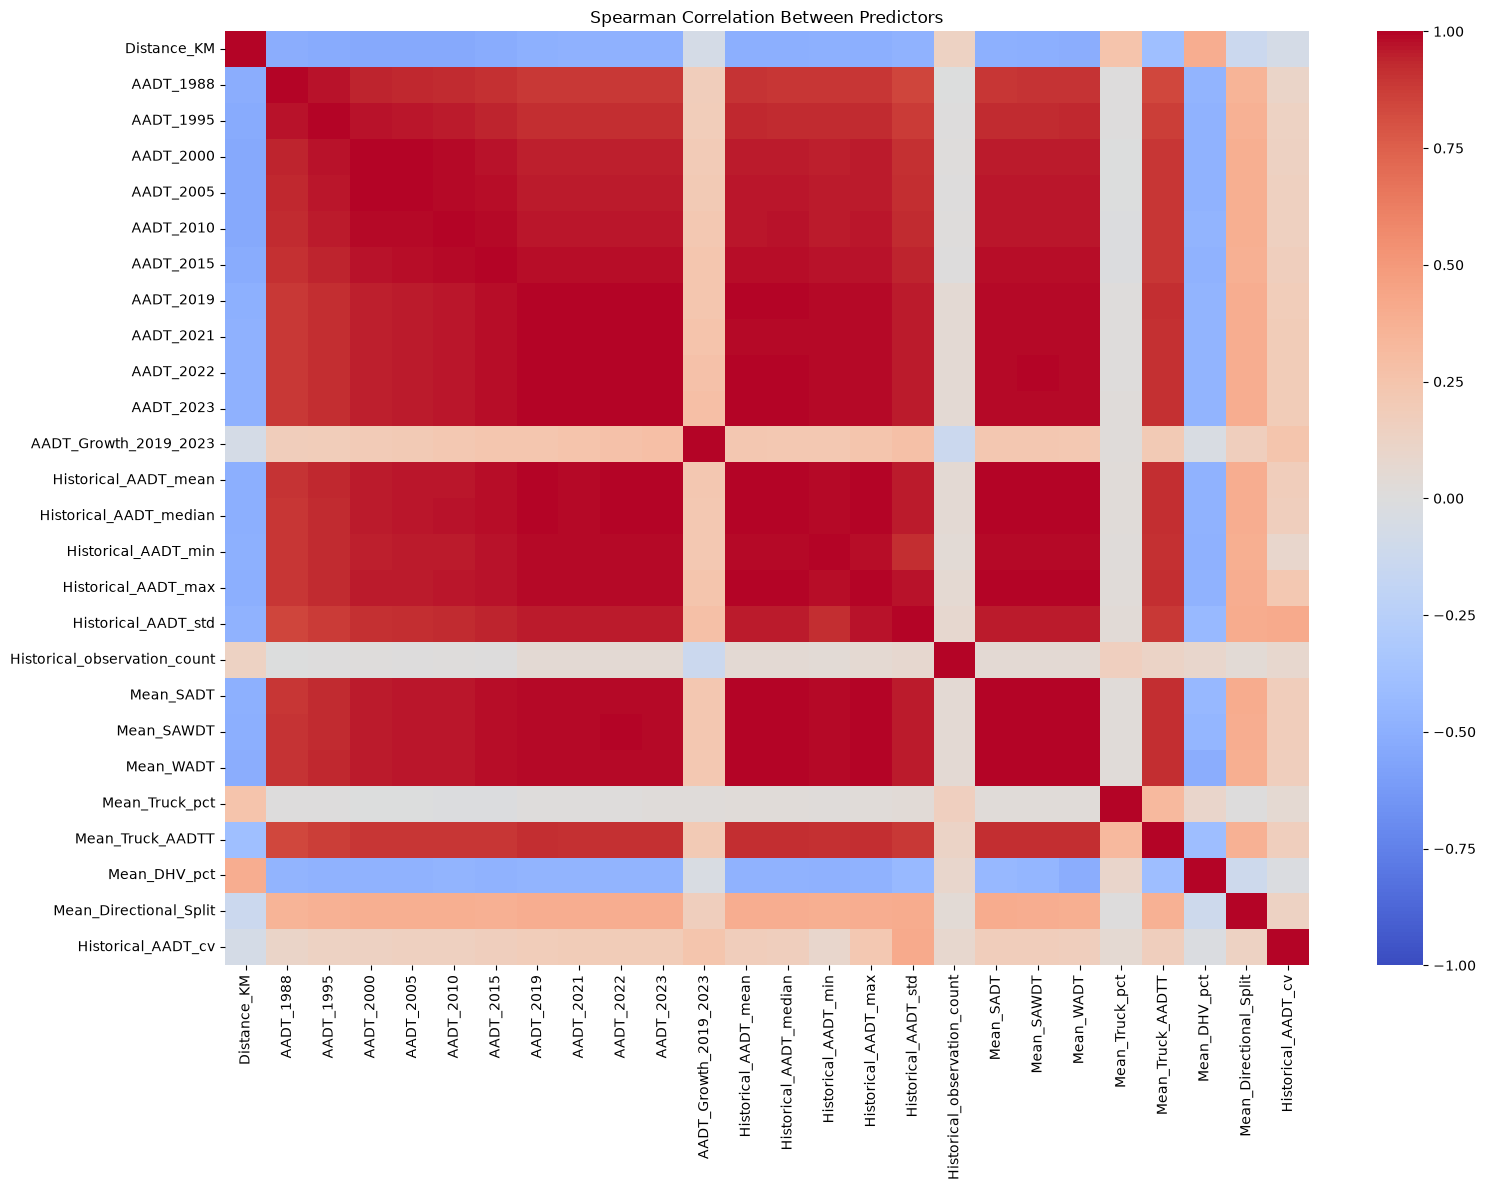

Number of highly correlated pairs: 116


,Variable 1,Variable 2,Correlation
0,AADT_1988,AADT_1995,0.9695
1,AADT_1995,AADT_2000,0.9716
2,AADT_1995,AADT_2005,0.9648
3,AADT_1995,AADT_2010,0.9550
4,AADT_2000,AADT_2005,0.9941
...,...,...,...
111,Historical_AADT_std,Mean_SAWDT,0.9555
112,Historical_AADT_std,Mean_WADT,0.9537
113,Mean_SADT,Mean_SAWDT,0.9997
114,Mean_SADT,Mean_WADT,0.9951


In [9]:
# Calculate Spearman correlations between predictors
correlation_matrix = train[numeric_predictors].corr(
    method="spearman"
)

# Visualize correlations
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Between Predictors")
plt.tight_layout()
plt.show()

# Identify highly correlated predictor pairs
high_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        correlation = correlation_matrix.iloc[i, j]

        if abs(correlation) >= 0.95:
            high_correlations.append({
                "Variable 1": correlation_matrix.columns[i],
                "Variable 2": correlation_matrix.columns[j],
                "Correlation": correlation
            })

high_correlation_df = pd.DataFrame(
    high_correlations,
    columns=["Variable 1", "Variable 2", "Correlation"]
)

print("Number of highly correlated pairs:",
      len(high_correlation_df))

display(high_correlation_df.round(4))

### Dimensionality reduction findings

The augmented dataset contains 29 candidate independent
variables after removing AADT_2020.

No constant variables were identified, so no variables
are removed based solely on low variability.

Spearman correlation analysis identified 116 predictor
pairs with an absolute correlation of at least 0.95.

Historical AADT and seasonal traffic measurements
contain substantial overlapping information.

We retain the augmented dataset for the initial regression
analysis and use correlation analysis to help guide
subsequent variable selection.

### Logarithmic transformation

Distance and traffic volumes exhibit right-skewed
distributions.

Following Tukey's ladder of powers, we investigate
logarithmic transformations to reduce skewness and
potentially improve linear regression relationships.

Transformations are examined using the training dataset
before being applied to the testing dataset.

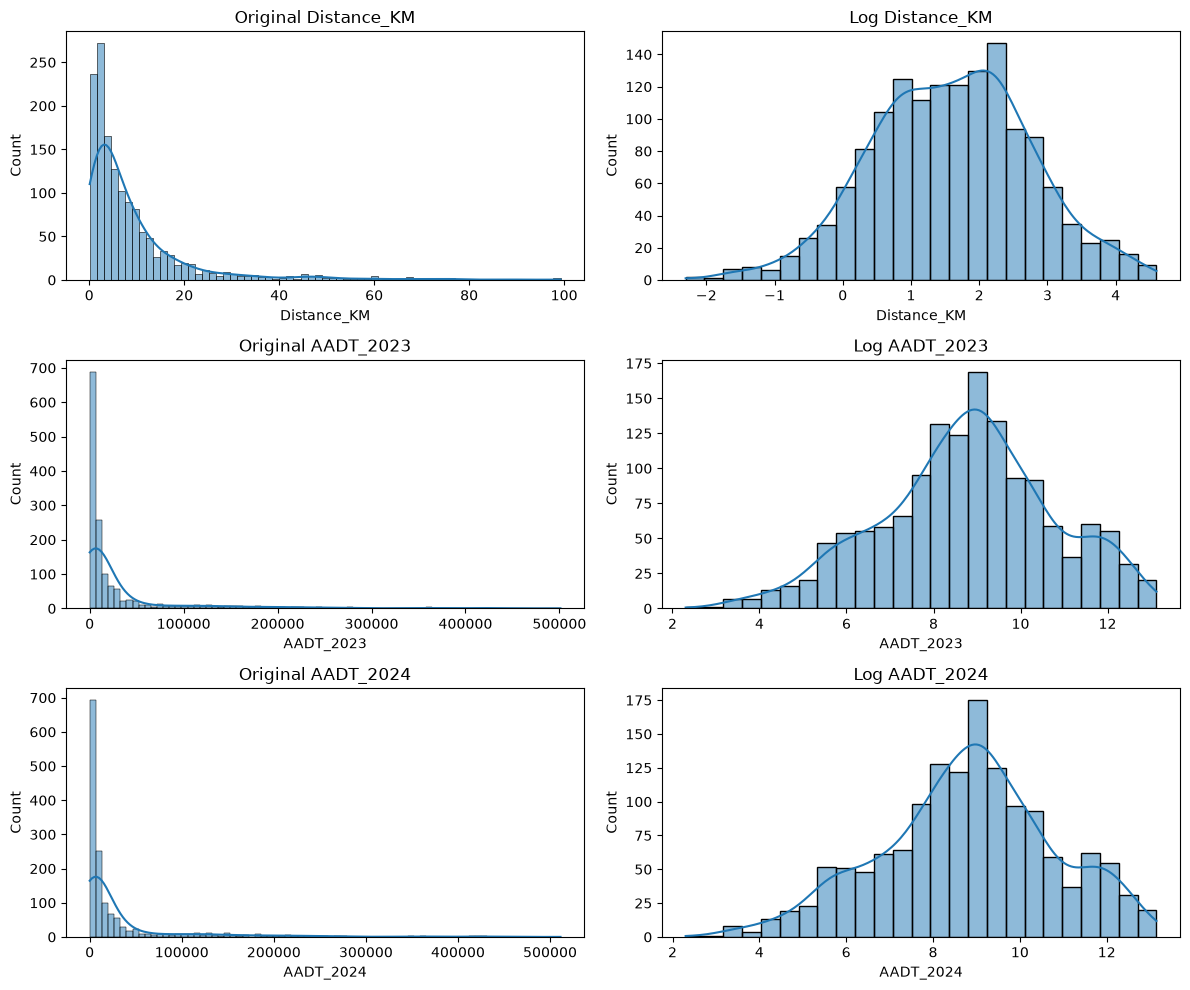

,Original Skewness,Log Skewness
Distance_KM,3.2967,-0.0869
AADT_2023,3.4212,-0.1952
AADT_2024,3.4123,-0.2060


In [10]:
# Examine original and logarithmic distributions
transform_variables = [
    "Distance_KM",
    "AADT_2023",
    "AADT_2024"
]

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for i, column in enumerate(transform_variables):
    original = train[column]
    transformed = np.log(original)

    sns.histplot(
        original,
        kde=True,
        ax=axes[i, 0]
    )

    axes[i, 0].set_title(f"Original {column}")

    sns.histplot(
        transformed,
        kde=True,
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"Log {column}")

plt.tight_layout()
plt.show()

# Compare skewness before and after transformation
skewness_comparison = pd.DataFrame({
    "Original Skewness": [
        train[column].skew()
        for column in transform_variables
    ],
    "Log Skewness": [
        np.log(train[column]).skew()
        for column in transform_variables
    ]
}, index=transform_variables)

display(skewness_comparison.round(4))

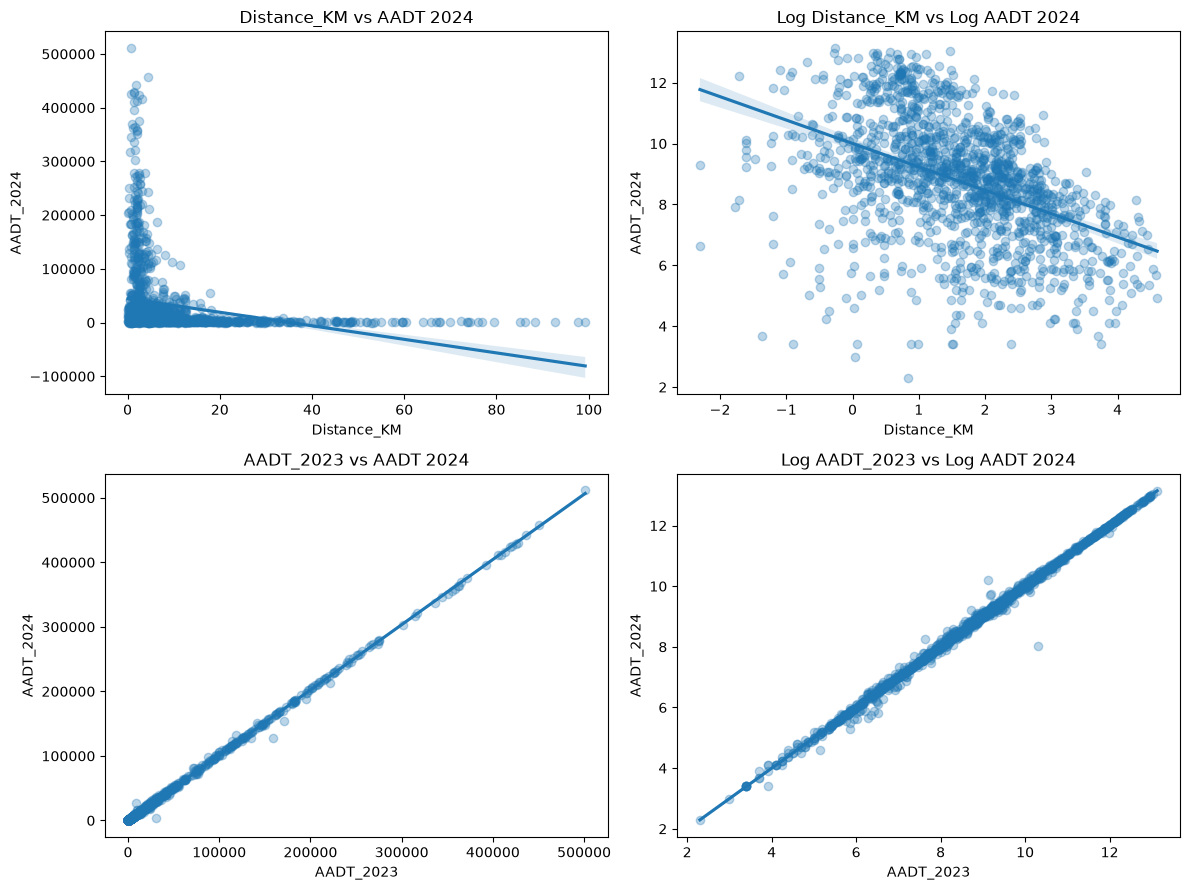

In [11]:
# Compare original and transformed relationships
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

predictors = ["Distance_KM", "AADT_2023"]

for i, column in enumerate(predictors):

    sns.regplot(
        x=train[column],
        y=train["AADT_2024"],
        ax=axes[i, 0],
        scatter_kws={"alpha": 0.3}
    )

    axes[i, 0].set_title(f"{column} vs AADT 2024")

    sns.regplot(
        x=np.log(train[column]),
        y=np.log(train["AADT_2024"]),
        ax=axes[i, 1],
        scatter_kws={"alpha": 0.3}
    )

    axes[i, 1].set_title(f"Log {column} vs Log AADT 2024")

plt.tight_layout()
plt.show()

### Transformation findings

The original distance and AADT distributions exhibit
substantial positive skewness.

Logarithmic transformations produce more symmetric
distributions and reveal a clearer linear relationship
between segment distance and traffic volume.

We therefore create logarithmic versions of distance,
2023 AADT and 2024 AADT for regression analysis.

The original variables are retained for interpretation
and evaluation in their original units.

In [12]:
# Apply logarithmic transformations to both datasets
for dataset in [train, test]:
    dataset["Log_Distance_KM"] = np.log(
        dataset["Distance_KM"]
    )

    dataset["Log_AADT_2023"] = np.log(
        dataset["AADT_2023"]
    )

    dataset["Log_AADT_2024"] = np.log(
        dataset["AADT_2024"]
    )

# Examine transformed variables
display(
    train[[
        "Log_Distance_KM",
        "Log_AADT_2023",
        "Log_AADT_2024"
    ]].describe().round(4)
)

,Log_Distance_KM,Log_AADT_2023,Log_AADT_2024
count,1447.0000,1447.0000,1447.0000
mean,1.5888,8.7709,8.7815
std,1.1568,1.9834,1.9919
min,-2.3026,2.3026,2.3026
25%,0.7571,7.5756,7.5756
50%,1.6194,8.8608,8.8888
75%,2.3632,10.0774,10.0900
max,4.5975,13.1248,13.1449


### Training and testing dataset validation

We compare the training and testing datasets to assess
whether the random split produced similar distributions.

The Kolmogorov-Smirnov test is used for numerical
variables, while the chi-square test is used for
categorical variables.

A significance level of 0.05 is used for both tests.

In [13]:
# Compare numerical distributions using the KS test
ks_results = []

for column in numeric_predictors + ["AADT_2024"]:

    statistic, p_value = ks_2samp(
        train[column],
        test[column]
    )

    ks_results.append({
        "Variable": column,
        "Training Mean": train[column].mean(),
        "Testing Mean": test[column].mean(),
        "KS Statistic": statistic,
        "P-value": p_value,
        "Significant Difference": p_value < 0.05
    })

ks_results = pd.DataFrame(ks_results)

display(ks_results.round(4))

print(
    "Variables with significant differences:",
    ks_results["Significant Difference"].sum()
)

,Variable,Training Mean,Testing Mean,KS Statistic,P-value,Significant Difference
0,Distance_KM,9.2592,8.7009,0.0512,0.4183,False
1,AADT_1988,15773.6420,14317.4862,0.0735,0.0836,False
2,AADT_1995,19968.7422,18413.7845,0.0568,0.2953,False
3,AADT_2000,23248.8735,20830.8564,0.0596,0.2448,False
4,AADT_2005,25626.9869,22554.3370,0.0597,0.2436,False
5,AADT_2010,27255.7844,23899.1436,0.0548,0.3357,False
6,AADT_2015,28927.6365,25190.3315,0.0673,0.1389,False
7,AADT_2019,30843.7526,26581.6851,0.0528,0.3806,False
8,AADT_2021,31435.7222,27014.4475,0.0548,0.3349,False
9,AADT_2022,31761.3822,27048.7569,0.0528,0.3808,False


Variables with significant differences: 0


In [14]:
# Group rare categorical levels using training frequencies
for column in categorical_columns:

    frequencies = train[column].value_counts(normalize=True)

    common_levels = frequencies[
        frequencies >= 0.01
    ].index

    for dataset in [train, test]:

        values = dataset[column].astype(str)

        dataset[column] = values.where(
            values.isin(common_levels),
            "Other"
        ).astype("category")

# Compare categorical distributions using chi-square
chi_results = []

for column in categorical_columns:

    contingency = pd.DataFrame({
        "Training": train[column].value_counts(),
        "Testing": test[column].value_counts()
    }).fillna(0)

    contingency = contingency[
        contingency.sum(axis=1) > 0
    ]

    statistic, p_value, dof, expected = chi2_contingency(
        contingency
    )

    chi_results.append({
        "Variable": column,
        "Chi-square Statistic": statistic,
        "Degrees of Freedom": dof,
        "P-value": p_value,
        "Minimum Expected Count": expected.min(),
        "Significant Difference": p_value < 0.05
    })

    print(f"\n{column}:")
    display(contingency)

chi_results = pd.DataFrame(chi_results)

display(chi_results.round(4))


Highway_Type:


,Training,Testing
Highway_Type,,
KING,872,227
FWY,339,87
SEC,232,46
Other,4,2



Region:


,Training,Testing
Region,,
CENTRAL,317,74
EAST,252,66
NORTHEASTERN,445,107
NORTHWESTERN,189,48
WEST,244,67



Pattern_Type:


,Training,Testing
Pattern_Type,,
C,194,43
CR,168,61
CTR,378,71
IC,124,30
IR,154,43
IT,21,4
LR,34,6
LT,176,59
Other,10,1


,Variable,Chi-square Statistic,Degrees of Freedom,P-value,Minimum Expected Count,Significant Difference
0,Highway_Type,3.0795,3,0.3795,1.2007,False
1,Region,0.9980,4,0.9101,47.4262,False
2,Pattern_Type,19.3622,11,0.0549,2.2012,False


### Training and testing validation findings

None of the 27 numerical variables showed statistically
significant distribution differences under the
Kolmogorov-Smirnov tests.

The chi-square tests also found no statistically significant
differences in the categorical distributions at the 5%
significance level.

However, Highway_Type and Pattern_Type contain small
expected category counts, so their chi-square results
should be interpreted cautiously.

Although some differences in descriptive statistics remain,
the results support retaining the current 80/20 split.

## 4. Simple linear regression

Two simple linear regression models are developed to
predict 2024 AADT.

The first model examines the relationship between highway
segment length and traffic volume.

The second model examines the relationship between
historical traffic volume in 2023 and traffic volume
in 2024.

Both models use logarithmic transformations and are
trained and evaluated using the same observations.

In [15]:
# Define the dependent variable
y_train = train["Log_AADT_2024"]
y_test = test["Log_AADT_2024"]

# Define the independent variable
X_train_1 = sm.add_constant(train[["Log_Distance_KM"]])
X_test_1 = sm.add_constant(test[["Log_Distance_KM"]])

# Fit the first simple linear regression model
slr1 = sm.OLS(y_train, X_train_1).fit()

# Display regression results
print(slr1.summary())

                            OLS Regression Results                            
Dep. Variable:          Log_AADT_2024   R-squared:                       0.200
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     360.2
Date:                Thu, 26 Nov 2026   Prob (F-statistic):           6.76e-72
Time:                        03:51:48   Log-Likelihood:                -2888.8
No. Observations:                1447   AIC:                             5782.
Df Residuals:                    1445   BIC:                             5792.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              10.0035      0.080    1

In [16]:
# Define the second independent variable
X_train_2 = sm.add_constant(train[["Log_AADT_2023"]])
X_test_2 = sm.add_constant(test[["Log_AADT_2023"]])

# Fit the second simple linear regression model
slr2 = sm.OLS(y_train, X_train_2).fit()

# Display regression results
print(slr2.summary())

                            OLS Regression Results                            
Dep. Variable:          Log_AADT_2024   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 4.564e+05
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:51:48   Log-Likelihood:                 1116.3
No. Observations:                1447   AIC:                            -2229.
Df Residuals:                    1445   BIC:                            -2218.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const            -0.0135      0.013     -1.008

### Model evaluation

F-statistics and R-squared values are calculated on the
logarithmic scale.

Predictions are converted back into original AADT units
before calculating RMSE. A smearing factor calculated
from training residuals is used to account for potential
retransformation bias.

In [17]:
# Evaluate regression models in original AADT units
def evaluate_model(name, model, X_train, X_test):

    # Calculate logarithmic predictions
    train_log_pred = model.predict(X_train)
    test_log_pred = model.predict(X_test)

    # Correct retransformation bias using training residuals
    smearing_factor = np.exp(model.resid).mean()

    # Convert predictions back to original traffic units
    train_pred = np.exp(train_log_pred) * smearing_factor
    test_pred = np.exp(test_log_pred) * smearing_factor

    # Calculate RMSE in original AADT units
    train_rmse = np.sqrt(
        mean_squared_error(train["AADT_2024"], train_pred)
    )

    test_rmse = np.sqrt(
        mean_squared_error(test["AADT_2024"], test_pred)
    )

    return {
        "Model": name,
        "F-statistic": model.fvalue,
        "F-test P-value": model.f_pvalue,
        "Training R-squared (Log Scale)": model.rsquared,
        "Testing R-squared (Log Scale)": r2_score(
        test["Log_AADT_2024"], test_log_pred
    ),
        "Adjusted R-squared (Log Scale)": model.rsquared_adj,
        "Training RMSE": train_rmse,
        "Testing RMSE": test_rmse
    }

# Compare the two simple regression models
slr_results = pd.DataFrame([
    evaluate_model(
        "SLR 1 - Distance",
        slr1, X_train_1, X_test_1
    ),
    evaluate_model(
        "SLR 2 - Historical AADT",
        slr2, X_train_2, X_test_2
    )
])

display(slr_results.round(4))

,Model,F-statistic,F-test P-value,Training R-squared (Log Scale),Testing R-squared (Log Scale),Adjusted R-squared (Log Scale),Training RMSE,Testing RMSE
0,SLR 1 - Distance,360.2347,0.0,0.1996,0.1872,0.1990,70757.3399,63158.6396
1,SLR 2 - Historical AADT,456373.1455,0.0,0.9968,0.9981,0.9968,2182.8042,1528.3398


### Simple linear regression findings

Both regression models are statistically significant
based on their F-tests.

The distance model explains approximately 20% of the
variation in log-transformed 2024 AADT, while the
historical AADT model explains approximately 99.68%.

The historical AADT model also achieves a substantially
lower testing RMSE of 1,528.34 compared with 63,158.64
for the distance model.

Therefore, 2023 AADT is a considerably stronger
individual predictor of 2024 traffic volume.

However, the residual normality tests indicate that
the regression assumptions are not fully satisfied.

## 5. Multiple linear regression

The initial multiple linear regression model includes
all eligible independent variables from the augmented
dataset.

The dependent variable remains log-transformed 2024 AADT.

We evaluate the overall model significance, adjusted
R-squared, individual predictor significance and
prediction errors.

Backward variable selection is subsequently applied to
develop a simpler and more interpretable model.

In [18]:
# Select all eligible independent variables
mlr_predictors = [
    column for column in study.columns
    if column not in [
        "AADT_2024",
        "Distance_KM",
        "AADT_2023"
    ]
]

# Include transformed predictors
mlr_predictors.extend([
    "Log_Distance_KM",
    "Log_AADT_2023"
])

# Construct the regression formula
formula = (
    "Log_AADT_2024 ~ " +
    " + ".join(mlr_predictors)
)

print("Number of predictors:", len(mlr_predictors))
print("\nRegression formula:")
print(formula)

# Fit the full multiple regression model
mlr_full = smf.ols(
    formula=formula,
    data=train
).fit()

print(mlr_full.summary())

Number of predictors: 29

Regression formula:
Log_AADT_2024 ~ AADT_1988 + AADT_1995 + AADT_2000 + AADT_2005 + AADT_2010 + AADT_2015 + AADT_2019 + AADT_2021 + AADT_2022 + AADT_Growth_2019_2023 + Historical_AADT_mean + Historical_AADT_median + Historical_AADT_min + Historical_AADT_max + Historical_AADT_std + Historical_observation_count + Mean_SADT + Mean_SAWDT + Mean_WADT + Mean_Truck_pct + Mean_Truck_AADTT + Mean_DHV_pct + Mean_Directional_Split + Historical_AADT_cv + Highway_Type + Region + Pattern_Type + Log_Distance_KM + Log_AADT_2023
                            OLS Regression Results                            
Dep. Variable:          Log_AADT_2024   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 1.052e+04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:51:49   Log-Likelihood:      

In [19]:
# Evaluate the full multiple regression model
mlr_full_results = pd.DataFrame([
    evaluate_model(
        "MLR - Full",
        mlr_full,
        train,
        test
    )
])

# Compare all three models
model_comparison = pd.concat(
    [slr_results, mlr_full_results],
    ignore_index=True
)

display(model_comparison.round(4))

# Check for exact linear dependencies
design_matrix = mlr_full.model.exog

print("Design matrix columns:", design_matrix.shape[1])
print("Design matrix rank:",
      np.linalg.matrix_rank(design_matrix))

# Examine individual coefficient significance
display(
    mlr_full.pvalues
    .sort_values(ascending=False)
    .to_frame("P-value")
)

,Model,F-statistic,F-test P-value,Training R-squared (Log Scale),Testing R-squared (Log Scale),Adjusted R-squared (Log Scale),Training RMSE,Testing RMSE
0,SLR 1 - Distance,360.2347,0.0,0.1996,0.1872,0.1990,70757.3399,63158.6396
1,SLR 2 - Historical AADT,456373.1455,0.0,0.9968,0.9981,0.9968,2182.8042,1528.3398
2,MLR - Full,10518.9476,0.0,0.9970,0.9979,0.9969,2504.5485,3581.3345


Design matrix columns: 45
Design matrix rank: 45


,P-value
Historical_observation_count,0.998979
Historical_AADT_min,0.977899
AADT_2005,0.911222
AADT_1988,0.907946
AADT_2000,0.895516
Mean_SAWDT,0.890395
Pattern_Type[T.Other],0.887185
Historical_AADT_cv,0.863213
Historical_AADT_median,0.862507
Mean_Truck_AADTT,0.857540


In [20]:
# Baseline: assume traffic remains unchanged
baseline_train_rmse = np.sqrt(
    mean_squared_error(
        train["AADT_2024"],
        train["AADT_2023"]
    )
)

baseline_test_rmse = np.sqrt(
    mean_squared_error(
        test["AADT_2024"],
        test["AADT_2023"]
    )
)

print("Baseline training RMSE:",
      round(baseline_train_rmse, 2))

print("Baseline testing RMSE:",
      round(baseline_test_rmse, 2))

Baseline training RMSE: 2042.5
Baseline testing RMSE: 1425.67


### Initial multiple regression findings

The initial multiple linear regression model contains
29 independent variables and 44 predictor coefficients
after categorical encoding.

Although the model achieves an R-squared of approximately
0.9970, its testing RMSE is substantially higher than
that of the historical AADT simple regression model.

Many independent variables are statistically insignificant,
and the large condition number indicates potential
multicollinearity or numerical scaling problems.

Backward variable selection is therefore applied to
reduce model complexity and remove predictors that
provide limited additional explanatory value.

### Backward variable selection

Backward selection begins with the full multiple linear
regression model.

At each iteration, the predictor with the largest
partial F-test p-value is removed if its p-value
exceeds 0.05.

Categorical variables are evaluated as complete terms.

The process continues until all remaining predictors
are statistically significant at the 5% level.

Only the training dataset is used for variable selection.

In [21]:
# Initialize backward variable selection
remaining_predictors = mlr_predictors.copy()

selection_history = []
significance_level = 0.05
iteration = 1

while remaining_predictors:

    # Fit the current model
    current_formula = (
        "Log_AADT_2024 ~ " +
        " + ".join(remaining_predictors)
    )

    current_model = smf.ols(
        current_formula,
        data=train
    ).fit()

    # Test each complete predictor term
    term_tests = current_model.wald_test_terms(
        scalar=True
    ).table

    term_pvalues = (
        term_tests["pvalue"]
        .drop("Intercept", errors="ignore")
        .astype(float)
    )

    # Identify the least significant predictor
    worst_predictor = term_pvalues.idxmax()
    worst_pvalue = term_pvalues.max()

    # Stop when all remaining predictors are significant
    if worst_pvalue <= significance_level:
        break

    selection_history.append({
        "Iteration": iteration,
        "Removed Predictor": worst_predictor,
        "P-value": worst_pvalue,
        "Adjusted R-squared": current_model.rsquared_adj,
        "Predictors Before Removal": len(remaining_predictors)
    })

    remaining_predictors.remove(worst_predictor)
    iteration += 1

# Display the variable removal process
selection_history = pd.DataFrame(selection_history)

display(selection_history.round(6))

print("Original predictors:", len(mlr_predictors))
print("Remaining predictors:", len(remaining_predictors))
print("\nSelected predictors:")

for predictor in remaining_predictors:
    print(predictor)

,Iteration,Removed Predictor,P-value,Adjusted R-squared,Predictors Before Removal
0,1,Historical_observation_count,0.998979,0.996885,29
1,2,Historical_AADT_min,0.977825,0.996887,28
2,3,AADT_2005,0.913018,0.996890,27
3,4,AADT_2000,0.944469,0.996892,26
4,5,Mean_SAWDT,0.881842,0.996894,25
5,6,AADT_1988,0.873369,0.996896,24
6,7,Historical_AADT_cv,0.867717,0.996898,23
7,8,Historical_AADT_median,0.840134,0.996900,22
8,9,Mean_Truck_AADTT,0.808706,0.996903,21
9,10,AADT_2010,0.738736,0.996905,20


Original predictors: 29
Remaining predictors: 7

Selected predictors:
AADT_2019
AADT_2021
AADT_2022
Mean_Truck_pct
Highway_Type
Region
Log_AADT_2023


In [22]:
# Construct the final regression formula
final_formula = (
    "Log_AADT_2024 ~ " +
    (" + ".join(remaining_predictors)
     if remaining_predictors else "1")
)

print("Final regression formula:")
print(final_formula)

# Fit the reduced multiple regression model
mlr_reduced = smf.ols(
    formula=final_formula,
    data=train
).fit()

print(mlr_reduced.summary())

Final regression formula:
Log_AADT_2024 ~ AADT_2019 + AADT_2021 + AADT_2022 + Mean_Truck_pct + Highway_Type + Region + Log_AADT_2023
                            OLS Regression Results                            
Dep. Variable:          Log_AADT_2024   R-squared:                       0.997
Model:                            OLS   Adj. R-squared:                  0.997
Method:                 Least Squares   F-statistic:                 3.889e+04
Date:                Thu, 26 Nov 2026   Prob (F-statistic):               0.00
Time:                        03:51:50   Log-Likelihood:                 1137.9
No. Observations:                1447   AIC:                            -2250.
Df Residuals:                    1434   BIC:                            -2181.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.02

In [23]:
# Evaluate the reduced multiple regression model
mlr_reduced_results = pd.DataFrame([
    evaluate_model(
        "MLR - Reduced",
        mlr_reduced,
        train,
        test
    )
])

# Include all regression models
model_comparison = pd.concat(
    [
        slr_results,
        mlr_full_results,
        mlr_reduced_results
    ],
    ignore_index=True
)

# Include the previous-year prediction benchmark
baseline_results = pd.DataFrame([{
    "Model": "Baseline - 2023 AADT",
    "Training RMSE": baseline_train_rmse,
    "Testing RMSE": baseline_test_rmse
}])

final_comparison = pd.concat(
    [model_comparison, baseline_results],
    ignore_index=True
)

display(final_comparison.round(4))

,Model,F-statistic,F-test P-value,Training R-squared (Log Scale),Testing R-squared (Log Scale),Adjusted R-squared (Log Scale),Training RMSE,Testing RMSE
0,SLR 1 - Distance,360.2347,0.0,0.1996,0.1872,0.1990,70757.3399,63158.6396
1,SLR 2 - Historical AADT,456373.1455,0.0,0.9968,0.9981,0.9968,2182.8042,1528.3398
2,MLR - Full,10518.9476,0.0,0.9970,0.9979,0.9969,2504.5485,3581.3345
3,MLR - Reduced,38889.1781,0.0,0.9969,0.9980,0.9969,2285.5303,3653.2609
4,Baseline - 2023 AADT,NaN,NaN,NaN,NaN,NaN,2042.4966,1425.6718


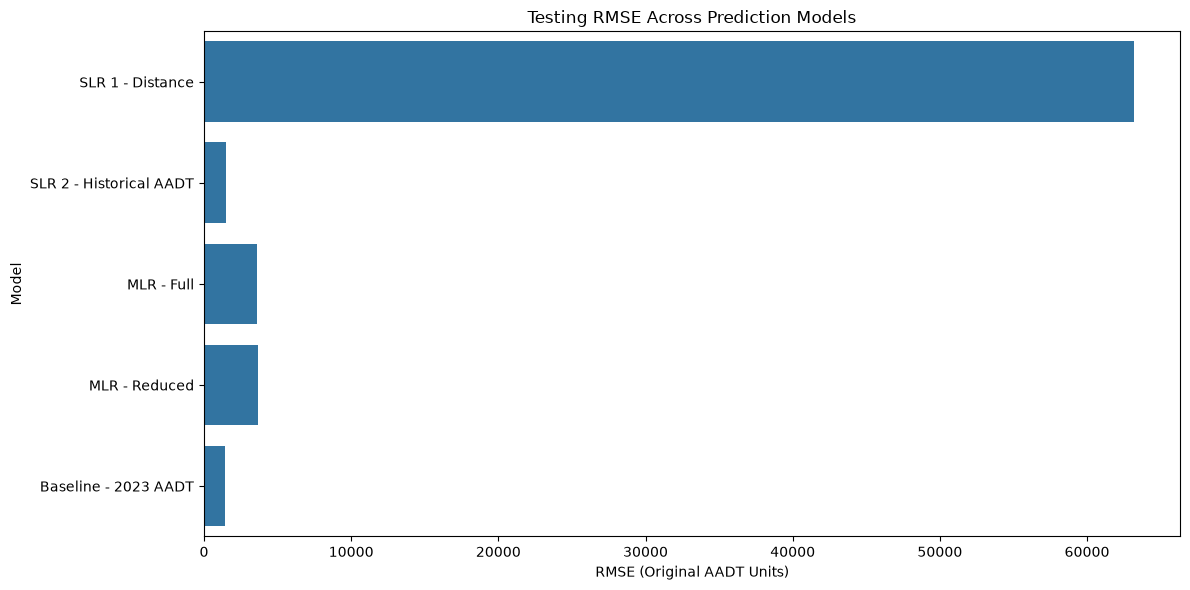

In [24]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=final_comparison,
    x="Testing RMSE",
    y="Model"
)

plt.title("Testing RMSE Across Prediction Models")
plt.xlabel("RMSE (Original AADT Units)")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

### Backward selection findings

Backward variable selection reduced the number of
independent variables from 29 to 7, representing a
75.86% reduction in dimensionality.

The reduced model retained nearly identical R-squared
and adjusted R-squared values compared with the full
multiple regression model.

However, testing RMSE increased from 3,581.33 to
3,653.26 vehicles per day.

The results demonstrate that reducing model complexity
and retaining statistically significant predictors
does not necessarily improve predictive accuracy.

The historical AADT simple regression model remains
the strongest regression model based on testing RMSE.

## 6. Regression diagnostics

Regression diagnostics are performed to evaluate
linearity, residual normality, constant error variance
and multicollinearity.

These diagnostics help identify limitations of the
regression models that may not be apparent from
R-squared and statistical significance alone.

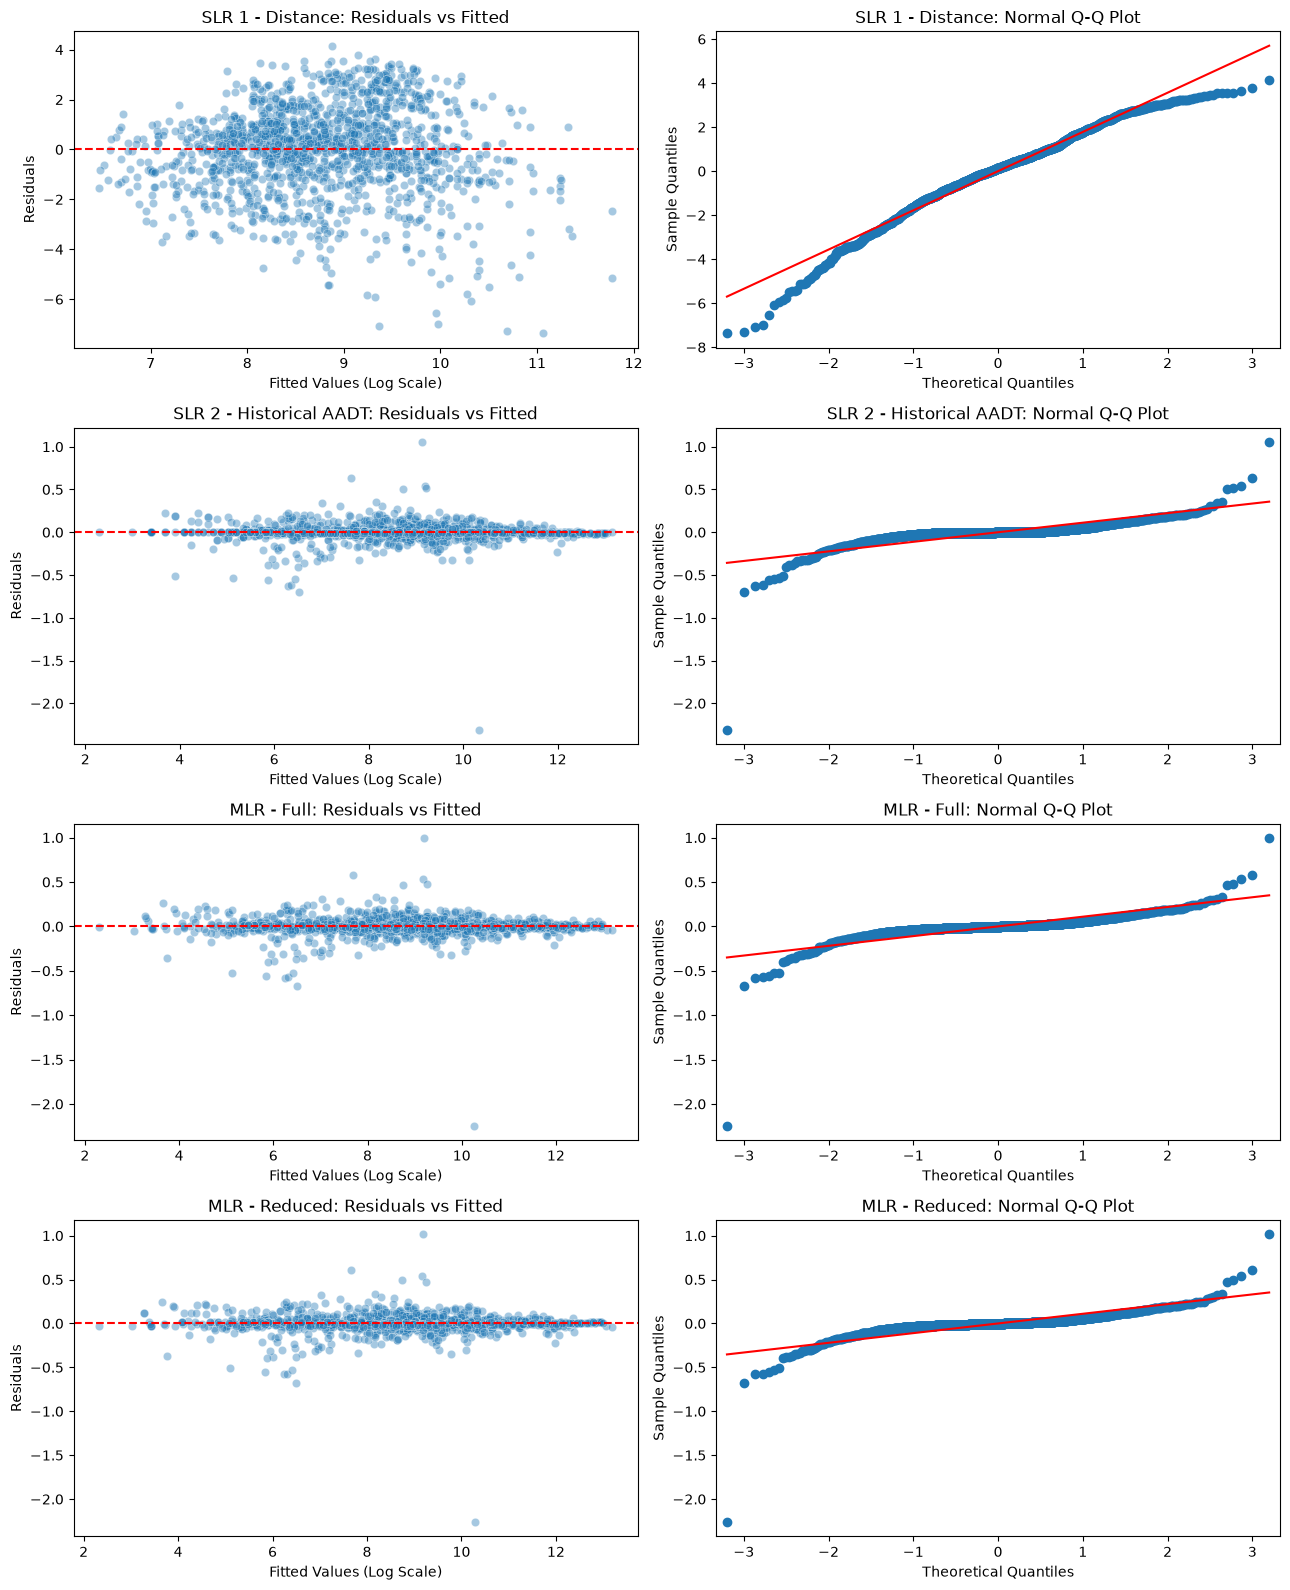

In [25]:
# Compare residual diagnostics for all regression models
diagnostic_models = {
    "SLR 1 - Distance": slr1,
    "SLR 2 - Historical AADT": slr2,
    "MLR - Full": mlr_full,
    "MLR - Reduced": mlr_reduced
}

fig, axes = plt.subplots(4, 2, figsize=(13, 16))

for i, (name, model) in enumerate(diagnostic_models.items()):

    # Residuals versus fitted values
    sns.scatterplot(
        x=model.fittedvalues,
        y=model.resid,
        alpha=0.4,
        ax=axes[i, 0]
    )

    axes[i, 0].axhline(0, color="red", linestyle="--")
    axes[i, 0].set_title(f"{name}: Residuals vs Fitted")
    axes[i, 0].set_xlabel("Fitted Values (Log Scale)")
    axes[i, 0].set_ylabel("Residuals")

    # Normal Q-Q plot
    sm.qqplot(
        model.resid,
        line="s",
        ax=axes[i, 1]
    )

    axes[i, 1].set_title(f"{name}: Normal Q-Q Plot")

plt.tight_layout()
plt.show()

In [26]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera

diagnostic_results = []

for name, model in diagnostic_models.items():

    # Normality test
    jb_stat, jb_p, skew, kurtosis = jarque_bera(
        model.resid
    )

    # Constant variance test
    bp_stat, bp_p, _, _ = het_breuschpagan(
        model.resid,
        model.model.exog
    )

    diagnostic_results.append({
        "Model": name,
        "Jarque-Bera Statistic": jb_stat,
        "Normality P-value": jb_p,
        "Breusch-Pagan Statistic": bp_stat,
        "Constant Variance P-value": bp_p,
        "Residual Skewness": skew,
        "Residual Kurtosis": kurtosis
    })

diagnostic_results = pd.DataFrame(diagnostic_results)

display(diagnostic_results.round(6))

,Model,Jarque-Bera Statistic,Normality P-value,Breusch-Pagan Statistic,Constant Variance P-value,Residual Skewness,Residual Kurtosis
0,SLR 1 - Distance,1.265633e+02,0.0,68.877631,0.000000,-0.603218,3.802308
1,SLR 2 - Historical AADT,1.105130e+06,0.0,0.245572,0.620210,-5.986980,137.856768
2,MLR - Full,1.042466e+06,0.0,30.030513,0.946437,-5.896335,133.963039
3,MLR - Reduced,1.044437e+06,0.0,13.157195,0.357719,-5.848931,134.096266


In [27]:
from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

def calculate_vif(model):

    X = pd.DataFrame(
        model.model.exog,
        columns=model.model.exog_names
    )

    vif = pd.DataFrame({
        "Variable": X.columns,
        "VIF": [
            variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])
        ]
    })

    return (
        vif[vif["Variable"] != "Intercept"]
        .sort_values("VIF", ascending=False)
    )

print("Full model VIF:")
display(calculate_vif(mlr_full).round(4))

print("Reduced model VIF:")
display(calculate_vif(mlr_reduced).round(4))

Full model VIF:


,Variable,VIF
29,Historical_AADT_mean,30951.6760
37,Mean_WADT,11206.4370
35,Mean_SADT,7021.3683
36,Mean_SAWDT,5306.5025
26,AADT_2021,3991.4590
25,AADT_2019,3496.0347
32,Historical_AADT_max,2707.2999
30,Historical_AADT_median,2361.4593
27,AADT_2022,1446.3858
24,AADT_2015,529.8296


Reduced model VIF:


,Variable,VIF
9,AADT_2021,3376.0070
8,AADT_2019,1434.3998
10,AADT_2022,1230.1627
12,Log_AADT_2023,5.0862
3,Highway_Type[T.SEC],4.8643
1,Highway_Type[T.KING],3.5297
5,Region[T.NORTHEASTERN],3.4093
6,Region[T.NORTHWESTERN],2.6705
4,Region[T.EAST],1.9126
7,Region[T.WEST],1.8726


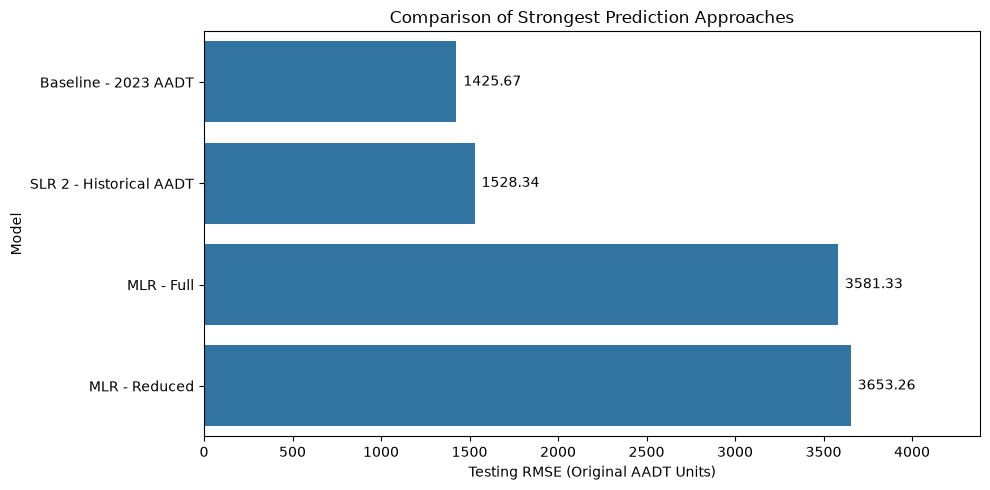

In [28]:
# Compare the four strongest prediction approaches
closer_comparison = final_comparison[
    final_comparison["Model"] != "SLR 1 - Distance"
].sort_values("Testing RMSE")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=closer_comparison,
    x="Testing RMSE",
    y="Model"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5)

plt.xlim(0, closer_comparison["Testing RMSE"].max() * 1.2)
plt.title("Comparison of Strongest Prediction Approaches")
plt.xlabel("Testing RMSE (Original AADT Units)")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

### Regression diagnostic findings

The Jarque-Bera test rejected residual normality for
all four regression models. The Q-Q plots also
identified substantial deviations from normality,
particularly in the tails of the distributions.

The Breusch-Pagan test identified significant
heteroscedasticity in the distance-based simple
linear regression model. The remaining models did
not show statistically significant heteroscedasticity
under this test.

Variance inflation factor analysis confirmed severe
multicollinearity among historical traffic predictors.

Although backward selection reduced the number of
predictors and lowered multicollinearity, several
historical AADT variables retained extremely high
VIF values.

These findings demonstrate that high R-squared values
do not guarantee that regression assumptions are
satisfied or that individual regression coefficients
are reliable.

## 7. Conclusion

This study investigated the prediction of 2024
Annual Average Daily Traffic (AADT) using highway
segment characteristics and historical traffic data.

The augmented dataset contained 1,809 highway
segments and 29 candidate independent variables
after removing the unavailable 2020 AADT variable.

The historical AADT simple linear regression model
performed substantially better than the distance-based
model, achieving an adjusted R-squared of 0.9968
on the logarithmic scale and a testing RMSE of
1,528.34 vehicles per day.

Backward selection reduced the multiple regression
model from 29 to 7 predictors. However, neither
multiple regression model improved predictive
accuracy compared with simple historical AADT
regression.

The previous-year AADT baseline achieved the lowest
testing RMSE of 1,425.67 vehicles per day, making it
the strongest overall prediction approach evaluated.

Therefore, the historical AADT simple linear
regression model is recommended as the preferred
regression model due to its simplicity, explanatory
power and predictive performance.

The baseline is recommended when prediction accuracy
alone is the primary objective.

Regression diagnostics identified non-normal residuals
and substantial multicollinearity, limiting the
reliability of individual coefficient interpretations.

Future work could investigate traffic growth,
regularized regression and validation across
additional years.

Among the multiple regression models, the seven-predictor
model offers a simpler alternative to the full model,
with nearly identical explanatory power and a slightly
higher testing RMSE. However, its remaining predictors
exhibit substantial multicollinearity, limiting the
interpretation of individual coefficients.